# Demo 1 · K-means: segmentar clientes de un shopping

**La pregunta de negocio.** Somos el equipo de marketing de un shopping. Tenemos datos de 200 clientes de la tarjeta de fidelidad y queremos armar campañas distintas para distintos tipos de clientes. Pero nadie nos dijo *qué* tipos de clientes hay: no hay una columna "segmento" para predecir.

Eso es aprendizaje **no supervisado**: no hay una respuesta correcta para aprender, buscamos estructura en los datos.

**Dataset:** *Mall Customers* (dataset de práctica muy usado, 200 clientes).
- `ingreso`: ingreso anual en miles de USD
- `score_gasto`: puntaje de 1 a 100 que el shopping le asigna según cuánto y qué tan seguido gasta
- `edad`, `genero`

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
PAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
pd.set_option("display.precision", 2)
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [2]:
df = pd.read_csv("data/mall_customers.csv").rename(columns={
    "CustomerID": "id", "Genre": "genero", "Age": "edad",
    "Annual Income (k$)": "ingreso", "Spending Score (1-100)": "score_gasto"})
df.head()

,id,genero,edad,ingreso,score_gasto
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [3]:
df.describe()

,id,edad,ingreso,score_gasto
count,200.00,200.00,200.00,200.00
mean,100.50,38.85,60.56,50.20
std,57.88,13.97,26.26,25.82
min,1.00,18.00,15.00,1.00
25%,50.75,28.75,41.50,34.75
50%,100.50,36.00,61.50,50.00
75%,150.25,49.00,78.00,73.00
max,200.00,70.00,137.00,99.00


## 1. Mirar antes de modelar

Con solo dos variables podemos graficar todo. **Antes de correr nada: ¿cuántos grupos ves?**

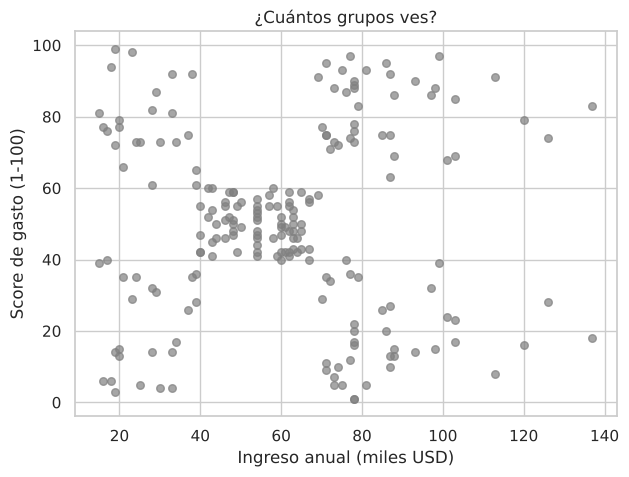

In [4]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(df.ingreso, df.score_gasto, s=30, color="gray", alpha=0.7)
ax.set_xlabel("Ingreso anual (miles USD)"); ax.set_ylabel("Score de gasto (1-100)")
ax.set_title("¿Cuántos grupos ves?");

## 2. Escalar las variables

K-means mide **distancias**. Si una variable está en miles y otra en unidades, la de miles domina la distancia sin que sea más importante. Por eso estandarizamos: cada variable pasa a tener media 0 y desvío 1.

(Acá las dos están en escalas parecidas, pero es un hábito que hay que tener siempre.)

In [5]:
X = df[["ingreso", "score_gasto"]]
scaler = StandardScaler()
X_esc = scaler.fit_transform(X)
X_esc[:5]

array([[-1.73899919, -0.43480148],
       [-1.73899919,  1.19570407],
       [-1.70082976, -1.71591298],
       [-1.70082976,  1.04041783],
       [-1.66266033, -0.39597992]])

## 3. Correr K-means con un K cualquiera

Tres líneas. `n_init=10` corre el algoritmo 10 veces con distintos puntos de arranque y se queda con la mejor (el resultado depende de dónde arrancan los centroides).

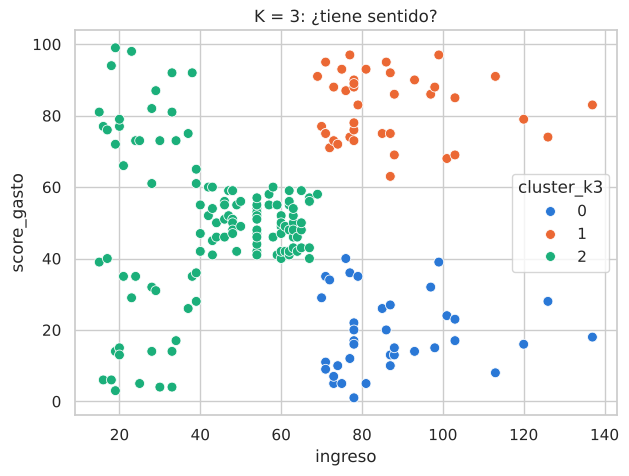

In [6]:
km = KMeans(n_clusters=3, n_init=10, random_state=42)
df["cluster_k3"] = km.fit_predict(X_esc)

fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(data=df, x="ingreso", y="score_gasto", hue="cluster_k3", palette=PAL[:3], s=50, ax=ax)
ax.set_title("K = 3: ¿tiene sentido?");

K-means **siempre** devuelve K grupos, aunque no tengan sentido. El algoritmo no te dice cuál es el K correcto: lo tenemos que elegir nosotros.

## 4. ¿Cuántos grupos? Codo y silhouette

- **Inercia**: suma de las distancias (al cuadrado) de cada cliente a su centroide. Siempre baja si agrego grupos; buscamos el punto donde deja de bajar mucho (el "codo").
- **Silhouette**: para cada cliente compara qué tan cerca está de su grupo vs. del grupo vecino. Va de -1 a 1; más alto = grupos más separados.

,K,inercia,silhouette
0,2,269.69,0.32
1,3,157.70,0.47
2,4,108.92,0.49
3,5,65.57,0.55
4,6,55.06,0.54
5,7,44.86,0.53
6,8,37.23,0.46
7,9,32.39,0.46
8,10,29.98,0.44


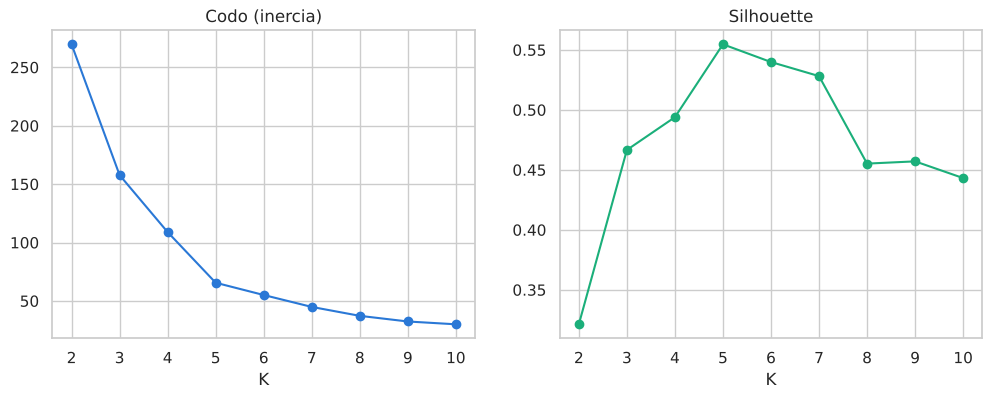

In [7]:
resultados = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_esc)
    resultados.append({"K": k, "inercia": km.inertia_, "silhouette": silhouette_score(X_esc, km.labels_)})
res = pd.DataFrame(resultados)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(res.K, res.inercia, marker="o", color=PAL[0]); axes[0].set_title("Codo (inercia)")
axes[1].plot(res.K, res.silhouette, marker="o", color=PAL[2]); axes[1].set_title("Silhouette")
for ax in axes: ax.set_xlabel("K")
res

Las dos métricas apuntan a **K = 5**.

Ojo: en la vida real casi nunca es tan claro. El K también es una **decisión de negocio**: si el equipo de marketing puede manejar 3 campañas, 8 segmentos no sirven de nada.

## 5. Ajustar el modelo final e interpretar

In [8]:
km5 = KMeans(n_clusters=5, n_init=10, random_state=42)
df["cluster"] = km5.fit_predict(X_esc)

# Los centroides están en escala estandarizada: los volvemos a las unidades originales
centroides = pd.DataFrame(scaler.inverse_transform(km5.cluster_centers_), columns=["ingreso", "score_gasto"])
centroides

,ingreso,score_gasto
0,55.30,49.52
1,86.54,82.13
2,25.73,79.36
3,88.20,17.11
4,26.30,20.91


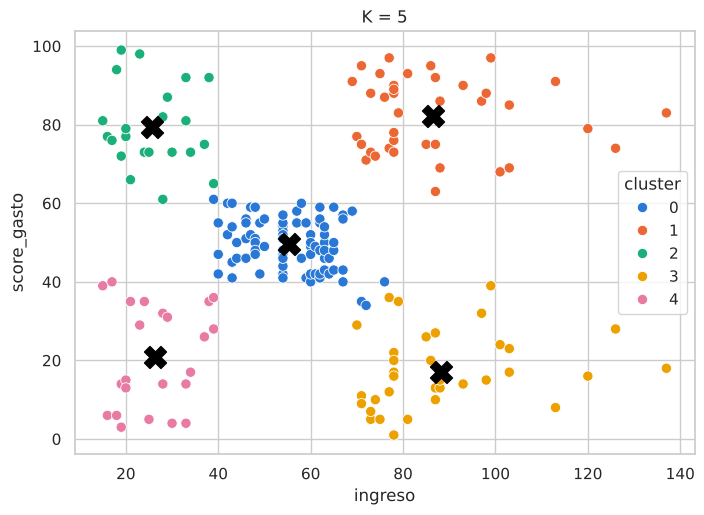

In [9]:
fig, ax = plt.subplots(figsize=(8, 5.5))
sns.scatterplot(data=df, x="ingreso", y="score_gasto", hue="cluster", palette=PAL[:5], s=55, ax=ax)
ax.scatter(centroides.ingreso, centroides.score_gasto, marker="X", s=250, color="black")
ax.set_title("K = 5");

**Lo más importante de la clase:** el algoritmo devuelve números (cluster 0, 1, 2...). Ponerles **nombre** y **acción** es trabajo nuestro, mirando el perfil de cada grupo. Sumamos la edad, que no usamos para agrupar, para ver si agrega información.

In [10]:
perfil = df.groupby("cluster").agg(
    clientes=("id", "count"),
    ingreso=("ingreso", "mean"),
    score_gasto=("score_gasto", "mean"),
    edad=("edad", "mean"),
    pct_mujeres=("genero", lambda g: (g == "Female").mean() * 100),
)
perfil

,clientes,ingreso,score_gasto,edad,pct_mujeres
cluster,,,,,
0,81,55.30,49.52,42.72,59.26
1,39,86.54,82.13,32.69,53.85
2,22,25.73,79.36,25.27,59.09
3,35,88.20,17.11,41.11,45.71
4,23,26.30,20.91,45.22,60.87


In [11]:
def nombrar(fila):
    if fila.ingreso > 70 and fila.score_gasto > 60: return "VIP"
    if fila.ingreso > 70 and fila.score_gasto < 40: return "Ahorradores con plata"
    if fila.ingreso < 40 and fila.score_gasto > 60: return "Gastadores impulsivos"
    if fila.ingreso < 40 and fila.score_gasto < 40: return "Cuidadosos"
    return "Clientes promedio"

perfil["segmento"] = perfil.apply(nombrar, axis=1)
df["segmento"] = df.cluster.map(perfil.segmento)
perfil.set_index("segmento").sort_values("ingreso")

,clientes,ingreso,score_gasto,edad,pct_mujeres
segmento,,,,,
Gastadores impulsivos,22,25.73,79.36,25.27,59.09
Cuidadosos,23,26.30,20.91,45.22,60.87
Clientes promedio,81,55.30,49.52,42.72,59.26
VIP,39,86.54,82.13,32.69,53.85
Ahorradores con plata,35,88.20,17.11,41.11,45.71


### ¿Y qué hacemos con esto?

| Segmento | Idea de acción |
|---|---|
| **VIP** (ingreso alto, gasta mucho) | Programa de fidelidad premium, eventos exclusivos. No perderlos. |
| **Ahorradores con plata** (ingreso alto, gasta poco) | El segmento con más potencial: ¿por qué no compran acá? Encuesta, marcas premium. |
| **Gastadores impulsivos** (ingreso bajo, gasta mucho, son jóvenes) | Promos, cuotas, cuidado con el riesgo crediticio. |
| **Cuidadosos** (ingreso bajo, gasta poco) | Descuentos puntuales, baja prioridad de inversión. |
| **Promedio** (el grupo más grande) | Comunicación masiva estándar. |

Notá que la **edad** separa bastante a los grupos aunque no la usamos para agrupar: los "impulsivos" son los más jóvenes. Eso es un hallazgo.

## 6. Para pensar en clase

1. ¿Qué pasa si **no** escalamos y una variable está en pesos y la otra en una escala de 1 a 10?
2. Agregá `edad` como tercera variable al clustering. ¿Cambian los grupos? ¿Son más fáciles o más difíciles de explicar?
3. ¿Qué pasa con K = 4 o K = 6? ¿Cuál le presentarías al gerente de marketing?

In [12]:
# Ejercicio 2: clustering con edad también
X3 = StandardScaler().fit_transform(df[["ingreso", "score_gasto", "edad"]])
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X3)
    print(f"K={k}  silhouette={silhouette_score(X3, km.labels_):.3f}")

K=2  silhouette=0.335
K=3  silhouette=0.358
K=4  silhouette=0.404
K=5  silhouette=0.417
K=6  silhouette=0.428
K=7  silhouette=0.417
K=8  silhouette=0.408
